<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AML4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mobile Price Prediction Using Machine Learning

The objective is predict the model with the lowest prediction error is selected as the best model.

Dataset Loaded Successfully

First 5 Records:
      Brand  RAM  Internal Memory  Battery Capacity  Screen Size  Camera  \
0     Apple    8              256              5600         6.66      16   
1     Apple    6              128              5000         6.84      32   
2      Vivo    8               64              4400         6.76      32   
3  Motorola   12              256              5500         6.47      16   
4      POCO   16              128              5500         6.40      12   

   Processor Speed   5G   Price  
0             3.46  Yes  102000  
1             2.89  Yes   92500  
2             3.09  Yes   55000  
3             1.87  Yes   45000  
4             2.12  Yes   40000  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Brand             500 non-null    object 
 1   RAM               500

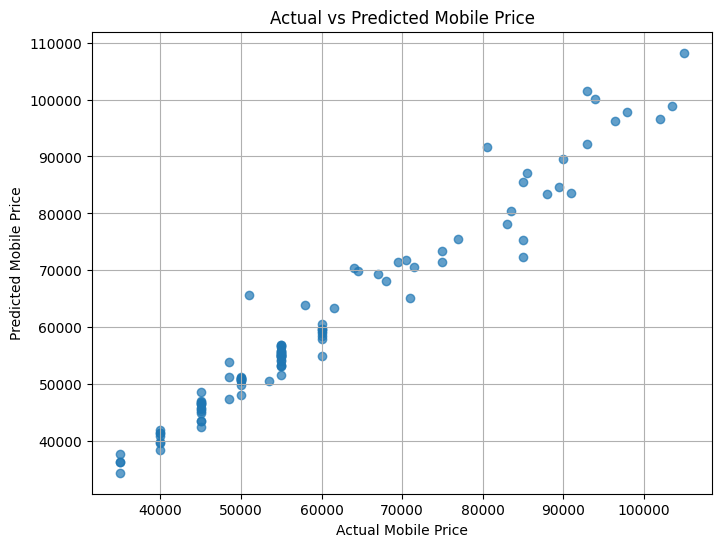


NEW MOBILE PRICE PREDICTION
Predicted Mobile Price: 64775.19


In [1]:
# ============================================================
# MOBILE PRICE PREDICTION USING MACHINE LEARNING
# ============================================================

# Import required libraries

import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Evaluation Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


# ============================================================
# STEP 1: LOAD THE DATASET
# ============================================================

# Read the mobile dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/mobile_price_500.csv")

print("Dataset Loaded Successfully")
print("\nFirst 5 Records:")
print(df.head())


# ============================================================
# STEP 2: DATASET INFORMATION
# ============================================================

print("\nDataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe(include="all"))


# ============================================================
# STEP 3: HANDLE MISSING VALUES
# ============================================================

# Identify numerical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns


# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns


# Fill missing numerical values using median
for column in numeric_columns:

    df[column] = df[column].fillna(
        df[column].median()
    )


# Fill missing categorical values using mode
for column in categorical_columns:

    if df[column].isnull().sum() > 0:

        df[column] = df[column].fillna(
            df[column].mode()[0]
        )


# ============================================================
# STEP 4: DEFINE INPUT FEATURES AND TARGET VARIABLE
# ============================================================

# Change "Price" if your target column has another name
target_column = "Price"


# Input features
X = df.drop(
    target_column,
    axis=1
)


# Target variable
y = df[target_column]


print("\nInput Features:")
print(X.columns)

print("\nTarget Variable:")
print(target_column)


# ============================================================
# STEP 5: IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()


categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()


print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# ============================================================
# STEP 6: DATA PREPROCESSING
# ============================================================

# Scale numerical features
numerical_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)


# Convert categorical features into numerical form
categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),

        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)


# ============================================================
# STEP 7: SPLIT DATA INTO TRAINING AND TESTING DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42

)


print("\nTraining Data Shape:")
print(X_train.shape)

print("\nTesting Data Shape:")
print(X_test.shape)


# ============================================================
# STEP 8: CREATE MACHINE LEARNING MODELS
# ============================================================

models = {

    "Linear Regression":
        LinearRegression(),

    "Random Forest":
        RandomForestRegressor(

            n_estimators=200,

            random_state=42

        ),

    "Gradient Boosting":
        GradientBoostingRegressor(

            n_estimators=200,

            learning_rate=0.05,

            random_state=42

        )

}


# ============================================================
# STEP 9: TRAIN AND EVALUATE MODELS
# ============================================================

results = []

trained_models = {}


for model_name, model in models.items():

    print("\n====================================")
    print("Training:", model_name)
    print("====================================")


    # Create complete pipeline
    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )
        ]
    )


    # Train the model
    pipeline.fit(
        X_train,
        y_train
    )


    # Make predictions
    predictions = pipeline.predict(
        X_test
    )


    # Calculate evaluation metrics
    mae = mean_absolute_error(
        y_test,
        predictions
    )


    mse = mean_squared_error(
        y_test,
        predictions
    )


    rmse = np.sqrt(
        mse
    )


    r2 = r2_score(
        y_test,
        predictions
    )


    # Store results
    results.append({

        "Model": model_name,

        "MAE": mae,

        "RMSE": rmse,

        "R2 Score": r2

    })


    # Store trained model
    trained_models[model_name] = pipeline


    # Print results
    print("MAE:", round(mae, 2))

    print("RMSE:", round(rmse, 2))

    print("R2 Score:", round(r2, 4))


# ============================================================
# STEP 10: COMPARE MODEL PERFORMANCE
# ============================================================

results_df = pd.DataFrame(
    results
)


# Sort models based on RMSE
results_df = results_df.sort_values(
    by="RMSE"
)


print("\n====================================")
print("MODEL COMPARISON")
print("====================================")

print(results_df)


# ============================================================
# STEP 11: SELECT BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]


best_model = trained_models[
    best_model_name
]


print("\n====================================")
print("BEST MODEL")
print("====================================")

print("Best Model:", best_model_name)


# ============================================================
# STEP 12: PREDICT USING THE BEST MODEL
# ============================================================

best_predictions = best_model.predict(
    X_test
)


# Create comparison dataframe
comparison = pd.DataFrame({

    "Actual Price": y_test.values,

    "Predicted Price": best_predictions

})


print("\nActual vs Predicted Prices:")

print(
    comparison.head(10)
)


# ============================================================
# STEP 13: VISUALIZE ACTUAL VS PREDICTED PRICE
# ============================================================

plt.figure(
    figsize=(8, 6)
)


plt.scatter(

    y_test,

    best_predictions,

    alpha=0.7

)


plt.xlabel(
    "Actual Mobile Price"
)


plt.ylabel(
    "Predicted Mobile Price"
)


plt.title(
    "Actual vs Predicted Mobile Price"
)


plt.grid()


plt.show()


# ============================================================
# STEP 14: FEATURE IMPORTANCE
# ============================================================

# Feature importance is available for Random Forest
if best_model_name == "Random Forest":

    model = best_model.named_steps["model"]

    print("\nRandom Forest Feature Importance:")

    print(model.feature_importances_)


# ============================================================
# STEP 15: PREDICT PRICE OF A NEW MOBILE
# ============================================================

# IMPORTANT:
# Replace the values below with columns
# that exactly match your dataset

new_mobile = pd.DataFrame({

    # Example numerical features

    "RAM": [8],

    "Internal Memory": [128],

    "Battery Capacity": [5000],

    "Screen Size": [6.5],

    "Camera": [50],

    "Processor Speed": [2.4],

    # Example categorical features

    "Brand": ["Samsung"],

    "5G": ["Yes"]

})


# Predict price

predicted_price = best_model.predict(
    new_mobile
)


print("\n====================================")
print("NEW MOBILE PRICE PREDICTION")
print("====================================")

print(
    "Predicted Mobile Price:",
    round(predicted_price[0], 2)
)


# ============================================================
# END OF PROGRAM
# ============================================================